# Chapter 5: Sentiment analysis with the perceptron algorithm

**Note:** This is the new version of the code, using scikit-learn instead of Turi Create (which was deprecated).
If you wish to see the original code in Turi Create that appears in the first edition of the book, please check [here](https://github.com/luisguiserrano/manning/blob/master/Chapter_05_Perceptron_Algorithm/DEPRECATED_Coding_perceptron_algorithm.ipynb).

### Importing packages

In [1]:
from matplotlib import pyplot as plt
import numpy as np
import random

### Plotting functions

In [2]:
def plot_points(features, labels, zoom=None, size=100):
    X = np.array(features)
    y = np.array(labels)
    happy = X[y == 1]
    sad = X[y == 0]
    plt.scatter(happy[:, 0], happy[:, 1], s=size, color='cyan',
                edgecolor='k', marker='^', label='happy', zorder=3)
    plt.scatter(sad[:, 0], sad[:, 1], s=size, color='red',
                edgecolor='k', marker='s', label='sad', zorder=3)
    plt.xlabel('aack')
    plt.ylabel('beep')
    plt.legend(loc='upper right')
    plt.grid(False)
    
    if zoom is not None:
        # Square window centered on the data, zoomed out by a factor of zoom
        cx = (X[:, 0].min() + X[:, 0].max()) / 2
        cy = (X[:, 1].min() + X[:, 1].max()) / 2
        r = zoom * max(X[:, 0].max() - X[:, 0].min(), X[:, 1].max() - X[:, 1].min()) / 2
        plt.xlim(cx - r, cx + r)
        plt.ylim(cy - r, cy + r)
        plt.gca().set_aspect('equal')

def draw_line(a, b, c, starting=-10, ending=10, **kwargs):
    # Plots the line a*x + b*y + c = 0
    if b == 0:
        # Vertical line x = -c/a
        plt.axvline(-c/a, **kwargs)
    else:
        x = np.linspace(starting, ending, 1000)
        plt.plot(x, -c/b - a*x/b, **kwargs)

def plot_boundary(features, labels, coefficients, intercept, zoom=3):
    # Plots the line coefficients[0]*x + coefficients[1]*y + intercept = 0
    draw_line(coefficients[0], coefficients[1], intercept,
              color='green', linewidth=2, label='Decision boundary')
    plot_points(features, labels, zoom=zoom, size=50)
    plt.title('Perceptron decision boundary and data points')
    plt.grid(False)
    plt.show()

### Defining and plotting our dataset

In [3]:
features = np.array([[1,0],[0,2],[1,1],[1,2],[1,3],[2,2],[2,3],[3,2]])
labels = np.array([0,0,0,0,1,1,1,1])

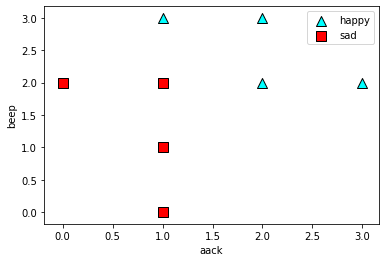

In [4]:
# Plotting the points
plot_points(features, labels)

# Uncomment the following line to see a good line fit for this data.
#draw_line(1,1,-3.5)

### Coding the perceptron trick

In [5]:
def score(weights, bias, features):
    return features.dot(weights) + bias

def step(x):
    if x >= 0:
        return 1
    else:
        return 0

def prediction(weights, bias, features):
    return step(score(weights, bias, features))

def error(weights, bias, features, label):
    pred = prediction(weights, bias, features)
    if pred == label:
        return 0
    else:
        return np.abs(score(weights, bias, features))

def mean_perceptron_error(weights, bias, features, labels):
    total_error = 0
    for i in range(len(features)):
        total_error += error(weights, bias, features[i], labels[i])
    return total_error/len(features)

In [6]:
# First perceptron trick
def perceptron_trick(weights, bias, features, label, learning_rate = 0.01):
    pred = prediction(weights, bias, features)
    if pred == label:
        return weights, bias
    else:
        if label==1 and pred==0:
            for i in range(len(weights)):
                weights[i] += features[i]*learning_rate
            bias += learning_rate
        elif label==0 and pred==1:
            for i in range(len(weights)):
                weights[i] -= features[i]*learning_rate
            bias -= learning_rate
    return weights, bias

In [7]:
# Shorter version of the perceptron trick
def perceptron_trick(weights, bias, features, label, learning_rate = 0.01):
    pred = prediction(weights, bias, features)
    for i in range(len(weights)):
        weights[i] += (label-pred)*features[i]*learning_rate
    bias += (label-pred)*learning_rate
    return weights, bias

Comparing the two classifiers on the dataset of table 5.3

In [8]:
features_small = np.array([[1,0],[0,1],[1,3],[3,2]])
labels_small = np.array([0,1,1,0])
print(mean_perceptron_error([1,2], -4, features_small, labels_small))   # Classifier 1: 1.25
print(mean_perceptron_error([-1,1], 0, features_small, labels_small))   # Classifier 2: 0.0

1.25
0.0


The perceptron trick examples ("Improved classifier 1" and "Improved classifier 2")

In [9]:
print(perceptron_trick([1,2], -4, np.array([2,5]), 0))   # ([0.98, 1.95], -4.01)
print(perceptron_trick([1,2], -4, np.array([2,0]), 1))   # ([1.02, 2.0], -3.99)

([0.98, 1.95], -4.01)
([1.02, 2.0], -3.99)


### Running the perceptron algorithm

In [10]:
def perceptron_algorithm(features, labels, learning_rate = 0.01, epochs = 200):
    weights = [1.0 for i in range(len(features[0]))]
    bias = 0.0
    errors = []
    lines = [(list(weights), bias)]
    for epoch in range(epochs):
        error = mean_perceptron_error(weights, bias, features, labels)
        errors.append(error)
        i = random.randint(0, len(features)-1)
        weights, bias = perceptron_trick(weights, bias, features[i], labels[i], learning_rate)
        # Keep only the lines where the classifier changed
        if (list(weights), bias) != lines[-1]:
            lines.append((list(weights), bias))
    # Draw the intermediate lines, from light (early) to dark (late)
    for k, (w, b) in enumerate(lines[:-1]):
        draw_line(w[0], w[1], b, color='grey', linewidth=0.8, linestyle='dotted',
                  alpha=0.25 + 0.6*k/len(lines))
    draw_line(weights[0], weights[1], bias, color='black', linewidth=2)
    plot_points(features, labels, zoom=3, size=50)
    plt.show()
    plt.scatter(range(epochs), errors)
    plt.xlabel('epochs')
    plt.ylabel('error')
    
    return weights, bias, errors

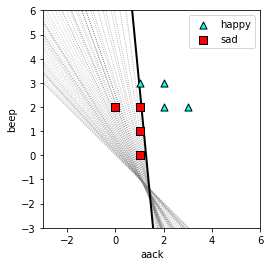

Weight of aack: 0.52
Weight of beep: 0.05
Bias: -0.66


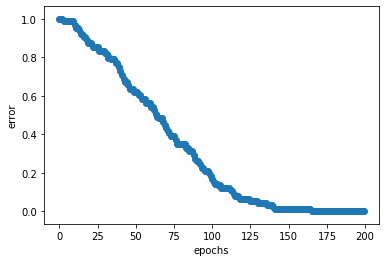

In [11]:
random.seed(0)
weights, bias, errors = perceptron_algorithm(features, labels)

print("Weight of aack:", round(weights[0], 2))
print("Weight of beep:", round(weights[1], 2))
print("Bias:", round(bias, 2))

### The perceptron algorithm using scikit-learn

In [12]:
from sklearn.linear_model import Perceptron

# Create a Perceptron model
perceptron = Perceptron()

# Fit the model to the data
perceptron.fit(features, labels)

# Predict the labels for the features
predictions = perceptron.predict(features)

print("Predictions:", predictions)

Predictions: [0 0 0 0 1 1 1 1]


In [13]:
# The coefficients of the model
coefficients = perceptron.coef_[0]
intercept = perceptron.intercept_[0]

print("Coefficients:", coefficients)
print("Intercept:", intercept)

Coefficients: [4. 2.]
Intercept: -9.0


This gives us the line with equation 4x_0 + 2x_1 - 9 = 0. Notice that the coefficients are not the same as the ones found above, but both lines classify every point correctly.

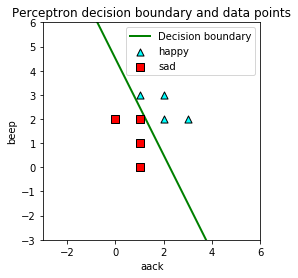

In [14]:
plot_boundary(features, labels, coefficients, intercept)